# A simple OrchModel: decomposition of target sound

We first need to be able to read in our FFT palate from the range in the FFT bank. The *palate* may be the *full bank* or a subset.|

In [4]:
import glob

ffts = glob.glob('../OldFFTBank/*.nbb')

In [5]:
ffts = [f.split('\\')[1].split('.')[0] for f in ffts]

In [6]:
ffts[:10]

['bsn-a2-ord-mf',
 'bsn-a3-ord-mf',
 'bsn-as1-ord-mf',
 'bsn-as2-ord-mf',
 'bsn-as3-ord-mf',
 'bsn-b1-ord-mf',
 'bsn-b2-ord-mf',
 'bsn-b3-ord-mf',
 'bsn-c2-ord-mf',
 'bsn-c3-ord-mf']

In [7]:
len(ffts)

979

In [8]:
instruments = set([f.split('-')[0] for f in ffts])
instruments = list(instruments)
instruments.sort()
instruments

['bsn',
 'btr',
 'cla',
 'ctb',
 'flu',
 'hrn',
 'mar',
 'obo',
 'pno',
 'tba',
 'tpt',
 'trb',
 'vla',
 'vlc',
 'vln']

# Reproduce a violin A4 with flutes

In [10]:
vln_a4_ord_mf = np.fromfile('../OldFFTBank/vln-a4-ord-mf.nbb', dtype='float32')
target = vln_a4_ord_mf

In [11]:
flu = [f for f in ffts if 'flu-' in f]
len(flu)

37

In [12]:
len(vln_a4_ord_mf)

2048

In [13]:
palate = np.zeros( (len(target), len(flu)) )
palate.shape

(2048, 37)

In [14]:
for i,f in enumerate(flu):
    x = np.fromfile('../OldFFTBank/' + f + '.nbb', dtype='float32')
    palate[:, i] = x

palate

array([[0.001, 0.001, 0.001, ..., 0.001, 0.001, 0.001],
       [0.   , 0.   , 0.   , ..., 0.   , 0.   , 0.   ],
       [0.   , 0.   , 0.   , ..., 0.   , 0.   , 0.   ],
       ...,
       [0.   , 0.   , 0.   , ..., 0.   , 0.   , 0.   ],
       [0.   , 0.   , 0.   , ..., 0.   , 0.   , 0.   ],
       [0.   , 0.   , 0.   , ..., 0.   , 0.   , 0.   ]])

In [15]:
palpseudoinv = np.linalg.pinv(palate)

In [16]:
w = palpseudoinv @ target 

In [17]:
w

array([ 0.32 , -0.044,  0.097,  0.002, -0.002, -0.001,  0.001,  0.   ,
        0.007,  0.14 , -0.043,  0.009,  0.001, -0.015,  0.011,  0.003,
       -0.007,  0.005,  0.007,  0.013, -0.005,  0.002, -0.015,  0.016,
        0.081,  0.004,  0.   ,  0.001,  0.001,  0.002,  0.001, -0.005,
       -0.012,  0.003,  0.027, -0.006, -0.001])

In [18]:
np.argsort(w)

array([ 1, 10, 22, 13, 32, 16, 35, 31, 20,  4, 36,  5, 26,  7, 28, 12, 27,
       30,  6, 21, 29,  3, 15, 33, 25, 17, 18,  8, 11, 14, 19, 23, 34, 24,
        2,  9,  0], dtype=int64)

**NOTE**: *negative* coefficients

# Non-negative coefficiants

We really should be solving our equation so that the coefficients will satisfy $w >= 0$

We do this by *minimizing* $|{\bf A}{\bf x} - {\bf b}|^2$ subject o $x_i > 0$.

In [19]:
from scipy.optimize import nnls  # non-negative least square

In [20]:
w = nnls(palate, target)

In [21]:
w

(array([0.297, 0.   , 0.091, 0.002, 0.   , 0.   , 0.   , 0.   , 0.007,
        0.033, 0.   , 0.   , 0.   , 0.   , 0.003, 0.003, 0.   , 0.001,
        0.005, 0.003, 0.   , 0.002, 0.   , 0.009, 0.088, 0.002, 0.   ,
        0.   , 0.   , 0.002, 0.001, 0.   , 0.   , 0.001, 0.025, 0.   ,
        0.   ]),
 0.00572177239212774)

In [22]:
w[0]

array([0.297, 0.   , 0.091, 0.002, 0.   , 0.   , 0.   , 0.   , 0.007,
       0.033, 0.   , 0.   , 0.   , 0.   , 0.003, 0.003, 0.   , 0.001,
       0.005, 0.003, 0.   , 0.002, 0.   , 0.009, 0.088, 0.002, 0.   ,
       0.   , 0.   , 0.002, 0.001, 0.   , 0.   , 0.001, 0.025, 0.   ,
       0.   ])

In [23]:
np.argsort(w[0])

array([36, 22, 20, 35, 16, 27, 13, 11, 10, 28, 32,  7,  6,  4, 31,  1,  5,
       12, 26, 33, 30, 17, 29, 25, 21,  3, 14, 19, 15, 18,  8, 23, 34,  9,
       24,  2,  0], dtype=int64)

In [24]:
projected = palate @ w[0]

In [25]:
projected

array([0.001, 0.   , 0.   , ..., 0.   , 0.   , 0.   ])

(20, 2048)

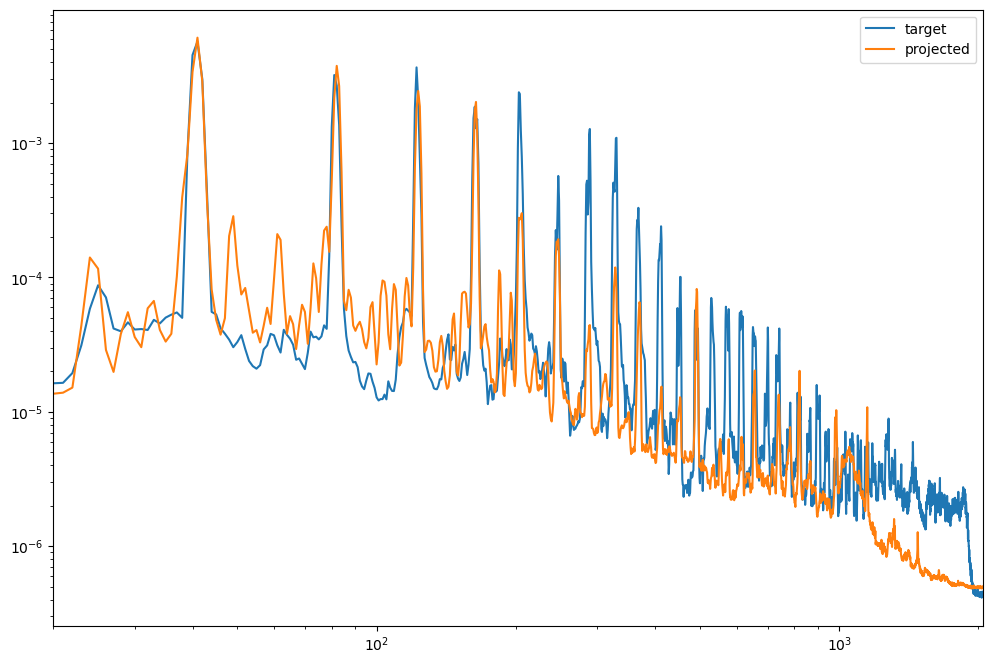

In [26]:
%matplotlib inline
setPLTdisplay(12,8)

plt.plot(range(len(target)), target, label='target')
plt.plot(range(len(target)), projected, label='projected')
plt.legend()
plt.yscale('log')
plt.xscale('log')
plt.xlim(20,len(target))

In [28]:
wind = np.argsort(-w[0])
wcoeffs = (w[0])[wind]
wcoeffs

array([0.297, 0.091, 0.088, 0.033, 0.025, 0.009, 0.007, 0.005, 0.003,
       0.003, 0.003, 0.002, 0.002, 0.002, 0.002, 0.001, 0.001, 0.001,
       0.   , 0.   , 0.   , 0.   , 0.   , 0.   , 0.   , 0.   , 0.   ,
       0.   , 0.   , 0.   , 0.   , 0.   , 0.   , 0.   , 0.   , 0.   ,
       0.   ])

In [29]:
wind

array([ 0,  2, 24,  9, 34, 23,  8, 18, 15, 19, 14,  3, 21, 25, 29, 17, 30,
       33, 26, 12,  5, 32,  1, 28, 27, 31,  6, 22,  7, 20, 35, 16, 13, 11,
       10,  4, 36], dtype=int64)

In [30]:
np.array(flu)[wind]

array(['flu-a4-ord-mf', 'flu-a6-ord-mf', 'flu-e6-ord-mf', 'flu-c4-ord-mf',
       'flu-gs4-ord-mf', 'flu-e5-ord-mf', 'flu-b6-ord-mf',
       'flu-d6-ord-mf', 'flu-cs6-ord-mf', 'flu-ds4-ord-mf',
       'flu-cs5-ord-mf', 'flu-as4-ord-mf', 'flu-ds6-ord-mf',
       'flu-f4-ord-mf', 'flu-fs5-ord-mf', 'flu-d5-ord-mf',
       'flu-fs6-ord-mf', 'flu-g6-ord-mf', 'flu-f5-ord-mf',
       'flu-c7-ord-mf', 'flu-as6-ord-mf', 'flu-g5-ord-mf',
       'flu-a5-ord-mf', 'flu-fs4-ord-mf', 'flu-f6-ord-mf',
       'flu-g4-ord-mf', 'flu-b4-ord-mf', 'flu-e4-ord-mf', 'flu-b5-ord-mf',
       'flu-ds5-ord-mf', 'flu-gs5-ord-mf', 'flu-d4-ord-mf',
       'flu-cs4-ord-mf', 'flu-c6-ord-mf', 'flu-c5-ord-mf',
       'flu-as5-ord-mf', 'flu-gs6-ord-mf'], dtype='<U14')

## Select-a-Bank

One way: with *SelectMultiple*

In [31]:
import ipywidgets as widgets

selectwgt = widgets.SelectMultiple(
    options=instruments,
#     value='pineapple',
    description='Palate :',
    disabled=False
)
selectwgt

SelectMultiple(description='Palate :', options=('bsn', 'btr', 'cla', 'ctb', 'flu', 'hrn', 'mar', 'obo', 'pno',…

In [32]:
selectwgt.value

('btr', 'ctb')

Another way: a *table of radiobuttons*

In [33]:
selrbuts = []

for i in instruments:
    selrbuts.append(widgets.Checkbox(
        value=False,
        description=i,
        disabled=False))

In [34]:
widgets.GridBox(selrbuts, layout=widgets.Layout(grid_template_columns="repeat(5, 100px)"))

GridBox(children=(Checkbox(value=False, description='bsn'), Checkbox(value=False, description='btr'), Checkbox…

In [35]:
for i,inst in enumerate(instruments):
    print(i, inst, selrbuts[i].value)

0 bsn True
1 btr False
2 cla False
3 ctb False
4 flu False
5 hrn False
6 mar True
7 obo True
8 pno False
9 tba False
10 tpt False
11 trb False
12 vla False
13 vlc False
14 vln False


In [36]:
s = [instruments[i] for i in range(len(instruments)) if selrbuts[i].value==True ]
print(s)

bankbasis = [f  for i in s for f in ffts if i + '-' in f]
len(bankbasis)

['bsn', 'mar', 'obo']


123

In [37]:
#bankbasis

In [38]:
palate = np.zeros( (len(target), len(bankbasis)) )
palate.shape

(2048, 123)

In [41]:
for i,f in enumerate(bankbasis):
    x = np.fromfile('../OldFFTBank/' + f + '.nbb', dtype='float32')
    palate[:, i] = x

palate

array([[0.001, 0.001, 0.001, ..., 0.001, 0.001, 0.001],
       [0.001, 0.001, 0.001, ..., 0.   , 0.   , 0.   ],
       [0.   , 0.   , 0.   , ..., 0.   , 0.   , 0.   ],
       ...,
       [0.   , 0.   , 0.   , ..., 0.   , 0.   , 0.   ],
       [0.   , 0.   , 0.   , ..., 0.   , 0.   , 0.   ],
       [0.   , 0.   , 0.   , ..., 0.   , 0.   , 0.   ]])

In [42]:
w = nnls(palate, target)[0]

In [43]:
#w

In [46]:
projected = palate @ w

(20, 2048)

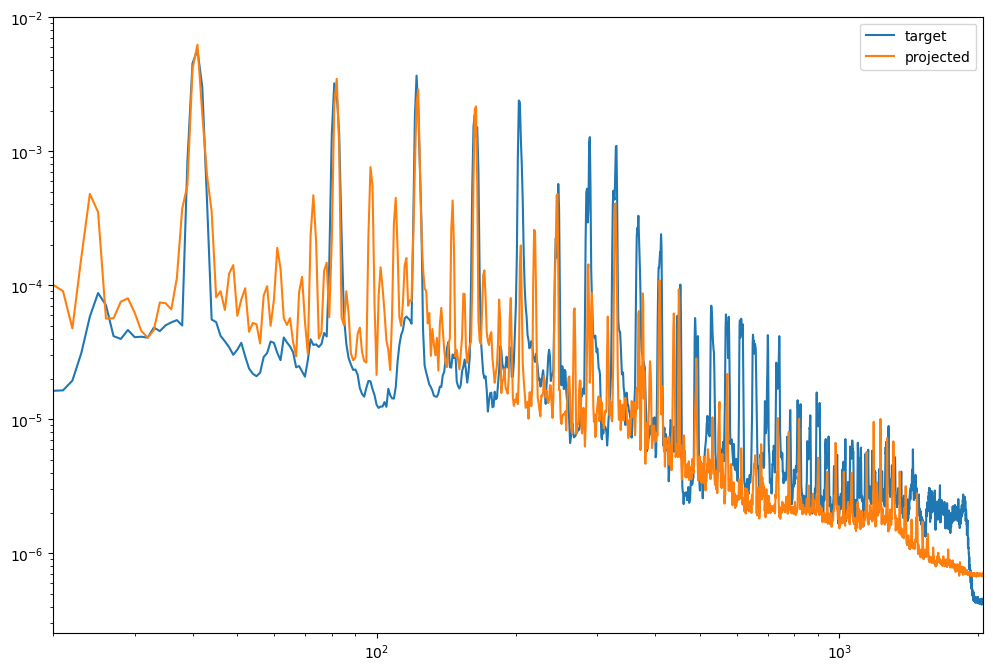

In [47]:
plt.plot(range(len(target)), target, label='target')
plt.plot(range(len(target)), projected, label='projected')
plt.legend()
plt.yscale('log')
plt.xscale('log')
plt.xlim(20,len(target))

## Keep only the top N notes

In [228]:
wind = np.argsort(-w)

In [229]:
for a,i in zip(w[wind], np.array(bankbasis)[wind]):
    print('{:.3f}'.format(a), i)

0.257 tpt-a4-ord-mf
0.153 hrn-a4-mut-mf
0.143 flu-a4-ord-mf
0.065 ctb-d3-mut-mf
0.059 tpt-ds4-ord-mf
0.029 tpt-ds5-hmo-mf
0.026 obo-d6-ord-mf
0.023 tpt-ds4-hmo-mf
0.021 trb-a4-stm-mf
0.019 flu-gs4-ord-mf
0.019 tpt-cs6-ord-mf
0.017 tpt-b3-hmo-mf
0.016 tpt-f4-hmo-mf
0.016 obo-c4-ord-mf
0.014 tpt-gs3-hmo-mf
0.013 cla-f4-ord-mf
0.013 trb-f2-ord-mf
0.009 tpt-fs5-ord-mf
0.008 flu-a6-ord-mf
0.008 bsn-as3-ord-mf
0.007 btr-b2-ord-mf
0.006 tpt-g4-hmo-mf
0.004 cla-fs3-ord-mf
0.004 flu-e5-ord-mf
0.003 btr-f3-ord-mf
0.003 flu-b6-ord-mf
0.002 flu-e6-ord-mf
0.001 obo-a5-ord-mf
0.001 cla-cs5-ord-mf
0.000 cla-cs6-ord-mf
0.000 cla-c4-ord-mf
0.000 obo-cs5-ord-mf
0.000 obo-b4-ord-mf
0.000 obo-b3-ord-mf
0.000 obo-as5-ord-mf
0.000 obo-c6-ord-mf
0.000 obo-as4-ord-mf
0.000 obo-as3-ord-mf
0.000 obo-a4-ord-mf
0.000 hrn-gs4-ord-mf
0.000 obo-cs4-ord-mf
0.000 obo-c5-ord-mf
0.000 obo-b5-ord-mf
0.000 bsn-a2-ord-mf
0.000 obo-d4-ord-mf
0.000 tpt-as4-hmo-mf
0.000 tpt-as3-ord-mf
0.000 tpt-as3-hmo-mf
0.000 tpt-a5-ord-mf


ValueError: x and y must have same first dimension, but have shapes (123,) and (37,)

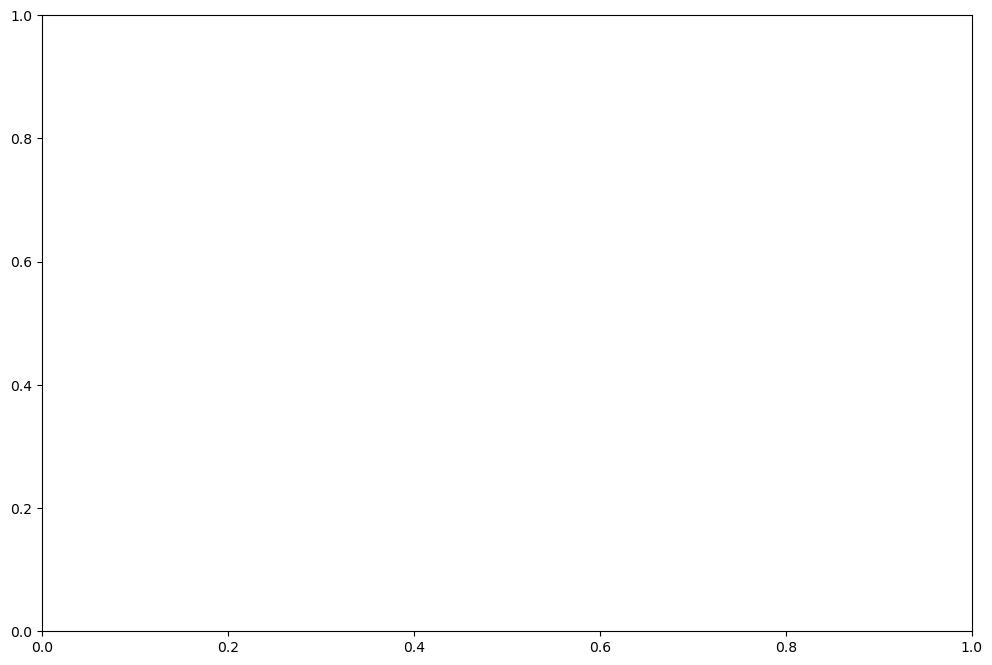

In [49]:
plt.plot(range(len(w)), w[wind], '.')
#plt.logscale('x')

In [283]:
keeptopN = 3

In [284]:
projtop = (palate[:,wind])[:,:keeptopN] @ (w[wind])[:keeptopN]

In [280]:
tpta4 = np.fromfile('../FFTBank/tpt-a4-ord-mf'+'.nbb', dtype='float32')

(20, 2048)

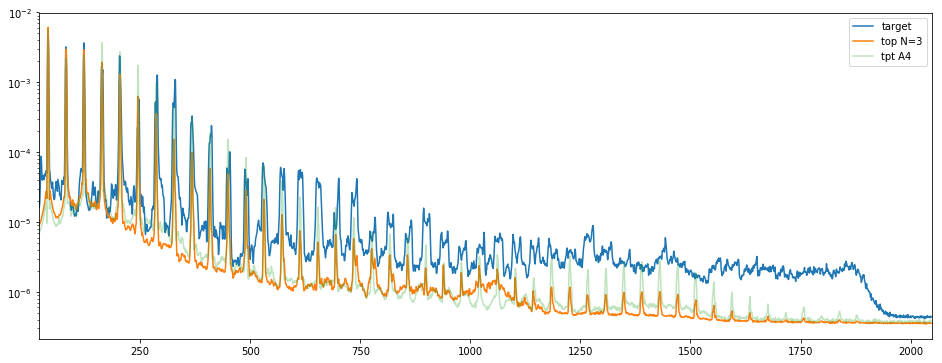

In [285]:
setPLTdisplay(16,6)

plt.plot(range(len(target)), target, label='target')
plt.plot(range(len(target)), projtop, label='top N={}'.format(keeptopN))
plt.plot(range(len(target)), tpta4, label='tpt A4', alpha=0.3)

#plt.plot(range(len(target)), projected, label='projected')

plt.legend()
plt.yscale('log')
#plt.xscale('log')
plt.xlim(20,len(target))